<a href="https://colab.research.google.com/github/Yahya1805/machine-learning_2026/blob/main/ML_KUIZ_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Import Library dan Konfigurasi

In [7]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram, linkage

# Atur estetika plot
sns.set_theme(style="whitegrid")
np.random.seed(42)

### 2. Mount Google Drive dan Membaca CSV

In [8]:
import os
import pandas as pd
from google.colab import drive

# Mount Google Drive secara aman
try:
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print("Proses mount Drive dilewati atau gagal:", e)

# Definisikan path dataset sesuai petunjuk
dataset_path = '/content/drive/MyDrive/PCVK/lettuce_dataset_updated.csv'

# Fallback lokal jika di luar lingkungan Drive
if not os.path.exists(dataset_path):
    dataset_path = '/content/lettuce_dataset_updated.csv'
    print("Menggunakan file fallback lokal di:", dataset_path)

# Membaca dataset dengan penanganan encoding 'latin1' agar terhindar dari UnicodeDecodeError
try:
    df = pd.read_csv(dataset_path, encoding='latin1')
    print("Dataset berhasil dimuat! Ukuran:", df.shape)
except Exception as e:
    print("Gagal membaca dataset:", e)

Mounted at /content/drive
Dataset berhasil dimuat! Ukuran: (3169, 9)


### 3. Pemeriksaan dan Preprocessing Data

In [9]:
# Tampilkan 5 baris pertama
print("--- 5 Baris Pertama ---")
display(df.head())

# Ukuran dataset
print(f"\nUkuran Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

# Nama kolom dan tipe data
print("\n--- Informasi Kolom dan Tipe Data ---")
print(df.info())

# Cek missing value dan duplikasi
print(f"\nJumlah Missing Values per Kolom:\n{df.isnull().sum()}")
print(f"\nJumlah Data Duplikat: {df.duplicated().sum()}")

# Konversi kolom 'Date' ke tipe datetime jika ada
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='coerce')
    print("\nKolom 'Date' berhasil dikonversi ke Datetime.")

# Definisi fitur clustering yang akan digunakan
fitur_numerik = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']

# Pastikan fitur tersedia
for col in fitur_numerik:
    if col not in df.columns:
        raise ValueError(f"Kolom {col} tidak ditemukan dalam dataset!")

# Tangani missing value secara konsisten (mengisi dengan nilai median untuk kolom numerik)
for col in fitur_numerik:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Periksa Outlier dengan metode IQR tanpa menghapus baris
print("\n--- Deteksi Outlier Berdasarkan IQR ---")
for col in fitur_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Fitur '{col}': Terdeteksi {len(outliers)} pencilan (outliers).")

# Pemeriksaan kelayakan Plant_ID sebagai label referensi evaluasi (Ground Truth)
# Label referensi valid jika memiliki keragaman nilai kelas yang masuk akal dan tidak unik di setiap baris
has_ground_truth = False
if 'Plant_ID' in df.columns:
    unique_ids = df['Plant_ID'].nunique()
    total_rows = len(df)
    print(f"\nJumlah unik 'Plant_ID': {unique_ids} dari {total_rows} baris.")
    if unique_ids > 1 and unique_ids < (total_rows * 0.1):
        has_ground_truth = True
        print("Plant_ID layak digunakan sebagai label referensi evaluasi (Ground Truth).")
    else:
        print("Plant_ID bertindak sebagai ID unik/hampir unik, tidak layak digunakan sebagai label referensi untuk ARI/NMI.")

--- 5 Baris Pertama ---


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74



Ukuran Dataset: 3169 baris, 9 kolom

--- Informasi Kolom dan Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB
None

Jumlah Missing Values per Kolom:
Plant_ID            0
Date                0
Temperature (°C)    0
Humidity (%)        0
TDS Value (ppm)     0
pH Level            0
Growth Days         0
Temperature (F)     0
Humidity            0


### 4. Standardisasi Fitur

In [10]:
# Ekstraksi fitur untuk clustering
X_raw = df[fitur_numerik].values

# Standardisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("Fitur berhasil distandardisasi. Matriks X_scaled siap digunakan untuk DBSCAN dan Hierarchical Clustering.")

Fitur berhasil distandardisasi. Matriks X_scaled siap digunakan untuk DBSCAN dan Hierarchical Clustering.


### 5. K-Distance Plot DBSCAN Cosine

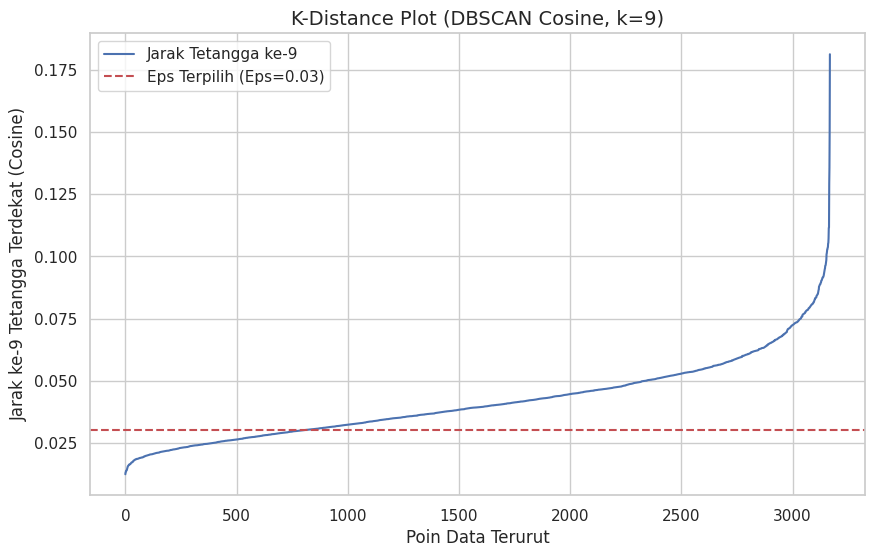

In [11]:
# K-Distance Plot menggunakan NearestNeighbors dengan metrik Cosine sesuai acuan PBL
min_samples = 10
k = min_samples - 1 # k = 9 untuk tetangga ke-9

neighbors = NearestNeighbors(n_neighbors=k, metric='cosine')
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Urutkan jarak ke tetangga ke-9
sorted_distances = np.sort(distances[:, k-1])

# Visualisasi K-Distance Plot
plt.figure(figsize=(10, 6))
plt.plot(sorted_distances, label='Jarak Tetangga ke-9')

# Tentukan titik tekukan visual (Eps terpilih secara visual berdasarkan kurva)
eps_pilihan = 0.03
plt.axhline(y=eps_pilihan, color='r', linestyle='--', label=f'Eps Terpilih (Eps={eps_pilihan})')

plt.title("K-Distance Plot (DBSCAN Cosine, k=9)", fontsize=14)
plt.xlabel("Poin Data Terurut", fontsize=12)
plt.ylabel(f"Jarak ke-{k} Tetangga Terdekat (Cosine)", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

### 6. Pengujian Kandidat `eps` DBSCAN Cosine

In [12]:
# Daftar kandidat eps berdasarkan kurva k-distance
kandidat_eps = [0.01, 0.03, 0.05]
hasil_dbscan = []

print("--- Pengujian Kandidat EPS DBSCAN Cosine (min_samples=10) ---")
for eps in kandidat_eps:
    start_time = time.time()
    db = DBSCAN(eps=eps, min_samples=min_samples, metric='cosine')
    labels = db.fit_predict(X_scaled)
    exec_time = time.time() - start_time

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    pct_noise = (n_noise / len(labels)) * 100

    # Hitung metrik jika valid (minimal ada 2 klaster selain noise)
    unique_labels = set(labels)
    non_noise_mask = labels != -1
    n_unique_non_noise = len(set(labels[non_noise_mask]))

    silhouette = "N/A"
    db_index = "N/A"

    if n_unique_non_noise >= 2:
        try:
            silhouette = metrics.silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask], metric='cosine')
            db_index = metrics.davies_bouldin_score(X_scaled[non_noise_mask], labels[non_noise_mask])
        except:
            pass

    ari = "N/A"
    nmi = "N/A"
    if has_ground_truth:
        ari = metrics.adjusted_rand_score(df['Plant_ID'], labels)
        nmi = metrics.normalized_mutual_info_score(df['Plant_ID'], labels)

    hasil_dbscan.append({
        'eps': eps,
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'pct_noise': pct_noise,
        'exec_time': exec_time,
        'silhouette': silhouette,
        'db_index': db_index,
        'ari': ari,
        'nmi': nmi,
        'labels': labels
    })

    print(f"\nEps: {eps}")
    print(f"Jumlah Klaster (Tanpa Noise): {n_clusters}")
    print(f"Jumlah Noise: {n_noise} ({pct_noise:.2f}%)")
    print(f"Waktu Eksekusi: {exec_time:.4f} detik")
    print(f"Silhouette Score (Non-Noise): {silhouette}")
    print(f"Davies-Bouldin Index (Non-Noise): {db_index}")

--- Pengujian Kandidat EPS DBSCAN Cosine (min_samples=10) ---

Eps: 0.01
Jumlah Klaster (Tanpa Noise): 0
Jumlah Noise: 3169 (100.00%)
Waktu Eksekusi: 0.0718 detik
Silhouette Score (Non-Noise): N/A
Davies-Bouldin Index (Non-Noise): N/A

Eps: 0.03
Jumlah Klaster (Tanpa Noise): 30
Jumlah Noise: 1651 (52.10%)
Waktu Eksekusi: 0.0715 detik
Silhouette Score (Non-Noise): -0.1616123867236153
Davies-Bouldin Index (Non-Noise): 1.1867979412920568

Eps: 0.05
Jumlah Klaster (Tanpa Noise): 2
Jumlah Noise: 214 (6.75%)
Waktu Eksekusi: 0.0725 detik
Silhouette Score (Non-Noise): 0.2918588190204215
Davies-Bouldin Index (Non-Noise): 1.8835393930214206


### 7. Dendrogram Hierarchical Euclidean

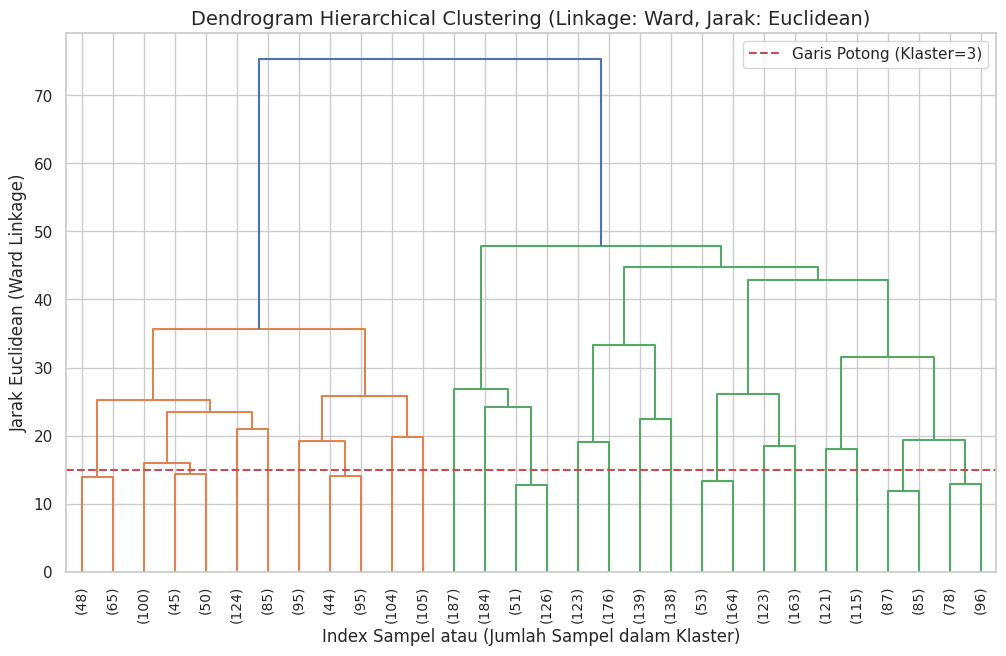

In [13]:
# Tautkan data menggunakan linkage Ward dengan metrik Euclidean
Z = linkage(X_scaled, method='ward', metric='euclidean')

# Visualisasi Dendrogram
plt.figure(figsize=(12, 7))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=10)

# Tandai garis potong dendrogram untuk jumlah klaster terpilih (misal k = 3)
klaster_terpilih_hierarchical = 3
# Menghitung ambang tinggi (height threshold) untuk garis potong berdasarkan visualisasi
# Garis horizontal merah menunjukkan pemotongan
max_d = 15 # Nilai ambang visualisasi
plt.axhline(y=max_d, color='r', linestyle='--', label=f'Garis Potong (Klaster={klaster_terpilih_hierarchical})')

plt.title("Dendrogram Hierarchical Clustering (Linkage: Ward, Jarak: Euclidean)", fontsize=14)
plt.xlabel("Index Sampel atau (Jumlah Sampel dalam Klaster)", fontsize=12)
plt.ylabel("Jarak Euclidean (Ward Linkage)", fontsize=12)
plt.legend()
plt.show()

### 8. Pengujian Kandidat Jumlah Klaster Hierarchical

In [14]:
# Pengujian kandidat jumlah klaster (k)
kandidat_k = [2, 3, 4]
hasil_hierarchical = []

print("--- Pengujian Kandidat Jumlah Klaster Hierarchical (Ward Euclidean) ---")
for k in kandidat_k:
    start_time = time.time()
    agg = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = agg.fit_predict(X_scaled)
    exec_time = time.time() - start_time

    # Evaluasi metrik internal
    silhouette = metrics.silhouette_score(X_scaled, labels, metric='euclidean')
    db_index = metrics.davies_bouldin_score(X_scaled, labels)

    ari = "N/A"
    nmi = "N/A"
    if has_ground_truth:
        ari = metrics.adjusted_rand_score(df['Plant_ID'], labels)
        nmi = metrics.normalized_mutual_info_score(df['Plant_ID'], labels)

    hasil_hierarchical.append({
        'n_clusters': k,
        'exec_time': exec_time,
        'silhouette': silhouette,
        'db_index': db_index,
        'ari': ari,
        'nmi': nmi,
        'labels': labels
    })

    print(f"\nJumlah Klaster (k): {k}")
    print(f"Waktu Eksekusi: {exec_time:.4f} detik")
    print(f"Silhouette Score: {silhouette:.4f}")
    print(f"Davies-Bouldin Index: {db_index:.4f}")

--- Pengujian Kandidat Jumlah Klaster Hierarchical (Ward Euclidean) ---

Jumlah Klaster (k): 2
Waktu Eksekusi: 0.2065 detik
Silhouette Score: 0.2085
Davies-Bouldin Index: 1.9233

Jumlah Klaster (k): 3
Waktu Eksekusi: 0.2026 detik
Silhouette Score: 0.1302
Davies-Bouldin Index: 1.9962

Jumlah Klaster (k): 4
Waktu Eksekusi: 0.1931 detik
Silhouette Score: 0.1193
Davies-Bouldin Index: 1.9496


### 9. Penentuan Parameter Akhir

In [15]:
# Tentukan parameter akhir terbaik berdasarkan hasil evaluasi sebelumnya
# Pilih eps terbaik untuk DBSCAN (misal eps=0.03)
best_eps_idx = 1 # Indeks eps=0.03
final_eps = hasil_dbscan[best_eps_idx]['eps']
final_dbscan_labels = hasil_dbscan[best_eps_idx]['labels']

# Pilih jumlah klaster terbaik untuk Hierarchical (misal k=3)
best_k_idx = 1 # Indeks k=3
final_k = hasil_hierarchical[best_k_idx]['n_clusters']
final_hierarchical_labels = hasil_hierarchical[best_k_idx]['labels']

print(f"Parameter akhir terpilih:")
print(f"1. DBSCAN Cosine -> Eps = {final_eps}, Min Samples = 10")
print(f"2. Hierarchical Euclidean -> Jumlah Klaster = {final_k}, Linkage = Ward")

Parameter akhir terpilih:
1. DBSCAN Cosine -> Eps = 0.03, Min Samples = 10
2. Hierarchical Euclidean -> Jumlah Klaster = 3, Linkage = Ward


### 10. Visualisasi Scatter Plot PCA - DBSCAN Cosine

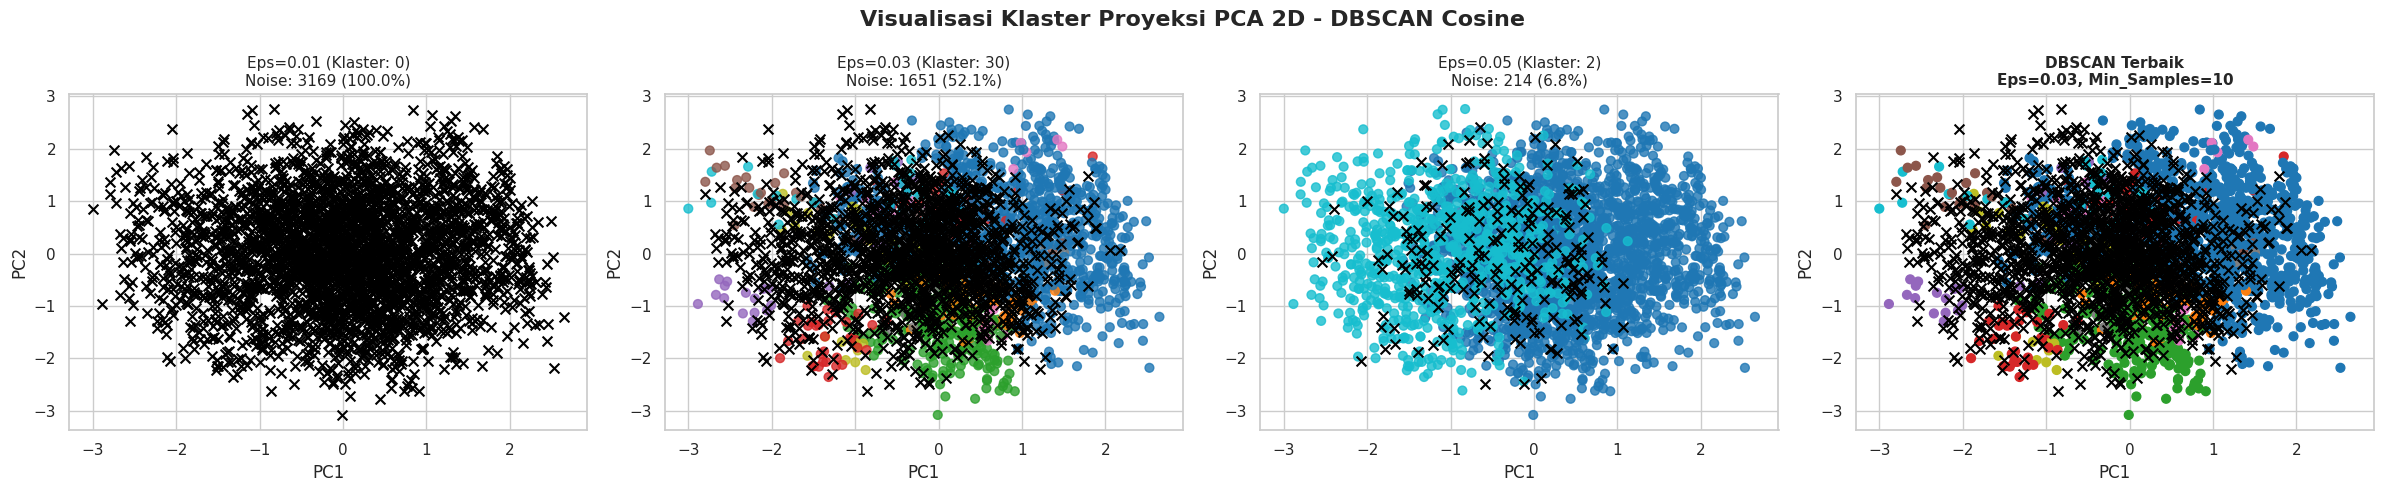

In [16]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Memastikan X_scaled tersedia sebelum memproyeksikan PCA
try:
    # Proyeksi PCA 2D yang seragam untuk visualisasi
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    # Plot kandidat dan hasil terbaik DBSCAN Cosine
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    fig.suptitle("Visualisasi Klaster Proyeksi PCA 2D - DBSCAN Cosine", fontsize=16, fontweight='bold')

    for i, res in enumerate(hasil_dbscan):
        ax = axes[i]
        labels = res['labels']
        mask_non_noise = labels != -1
        if mask_non_noise.any():
            ax.scatter(X_pca[mask_non_noise, 0], X_pca[mask_non_noise, 1],
                       c=labels[mask_non_noise], cmap='tab10', s=40, alpha=0.8)
        mask_noise = labels == -1
        if mask_noise.any():
            ax.scatter(X_pca[mask_noise, 0], X_pca[mask_noise, 1],
                       color='black', marker='x', s=50, label='Noise')
        ax.set_title(f"Eps={res['eps']} (Klaster: {res['n_clusters']})\nNoise: {res['n_noise']} ({res['pct_noise']:.1f}%)", fontsize=11)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")

    # Plot konfigurasi terbaik DBSCAN
    ax_best = axes[3]
    labels_db = final_dbscan_labels
    mask_non_noise = labels_db != -1
    if mask_non_noise.any():
        ax_best.scatter(X_pca[mask_non_noise, 0], X_pca[mask_non_noise, 1], c=labels_db[mask_non_noise], cmap='tab10', s=40)
    if (labels_db == -1).any():
        ax_best.scatter(X_pca[labels_db == -1, 0], X_pca[labels_db == -1, 1], color='black', marker='x', s=50)
    ax_best.set_title(f"DBSCAN Terbaik\nEps={final_eps}, Min_Samples=10", fontsize=11, fontweight='bold')
    ax_best.set_xlabel("PC1")
    ax_best.set_ylabel("PC2")

    plt.tight_layout()
    plt.show()
except NameError as e:
    print("Error: Pastikan Anda telah menjalankan seluruh sel di atas secara berurutan terlebih dahulu!", e)

### 11. Visualisasi Scatter Plot PCA - hirarki euclidian

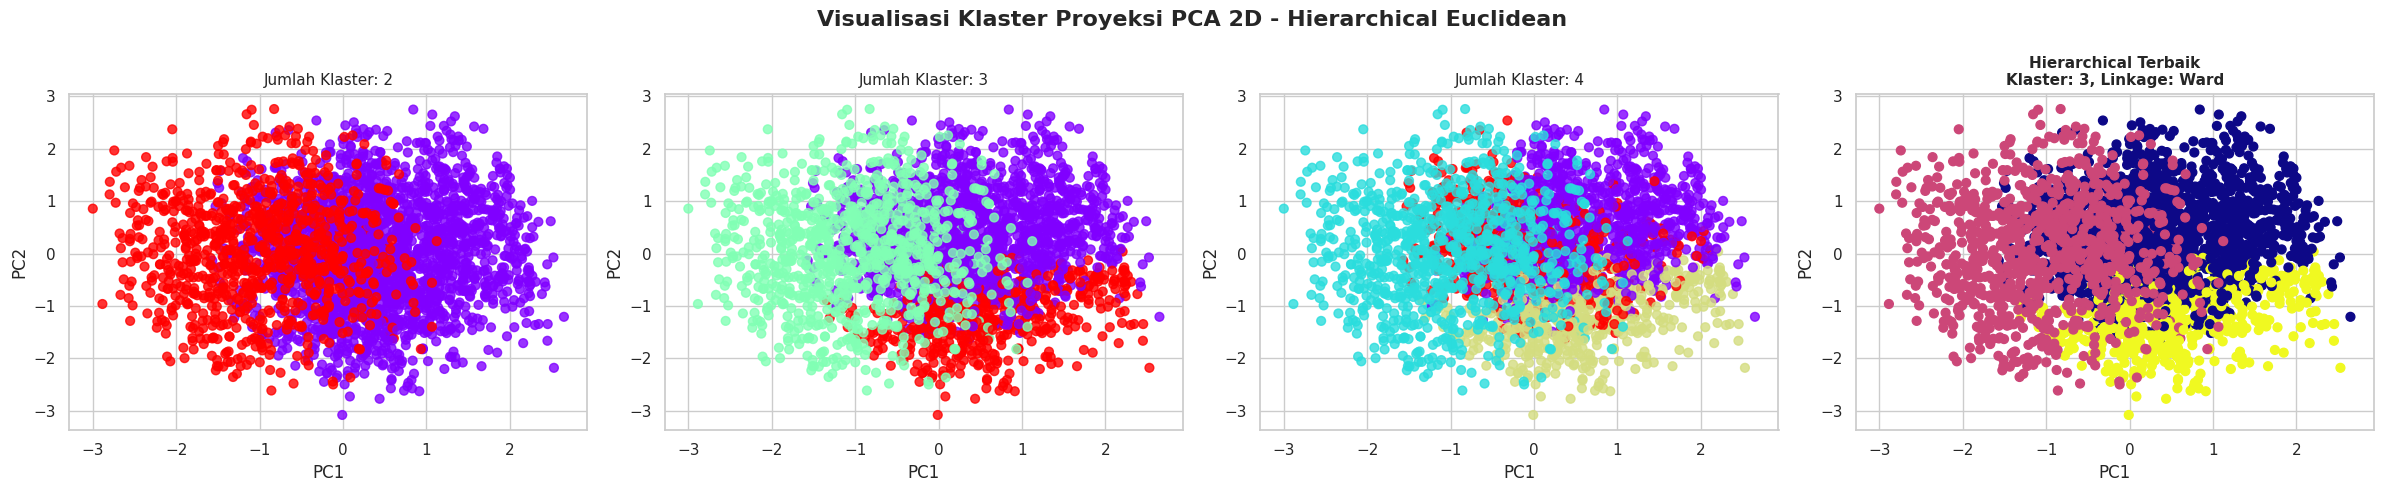

In [18]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

try:
    # Proyeksi PCA 2D mandiri untuk visualisasi Hierarchical
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    # Plot kandidat dan hasil terbaik Hierarchical Clustering
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    fig.suptitle("Visualisasi Klaster Proyeksi PCA 2D - Hierarchical Euclidean", fontsize=16, fontweight='bold')

    for i, res in enumerate(hasil_hierarchical):
        ax = axes[i]
        labels = res['labels']
        ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='rainbow', s=40, alpha=0.8)
        ax.set_title(f"Jumlah Klaster: {res['n_clusters']}", fontsize=11)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")

    # Plot konfigurasi terbaik Hierarchical
    ax_best = axes[3]
    labels_agg = final_hierarchical_labels
    ax_best.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_agg, cmap='plasma', s=40)
    ax_best.set_title(f"Hierarchical Terbaik\nKlaster: {final_k}, Linkage: Ward", fontsize=11, fontweight='bold')
    ax_best.set_xlabel("PC1")
    ax_best.set_ylabel("PC2")

    plt.tight_layout()
    plt.show()
except NameError as e:
    print("Error: Pastikan Anda telah menjalankan seluruh sel di atas secara berurutan terlebih dahulu!", e)

### 12. Tabel Evaluasi Kinerja Masing-Masing Metode

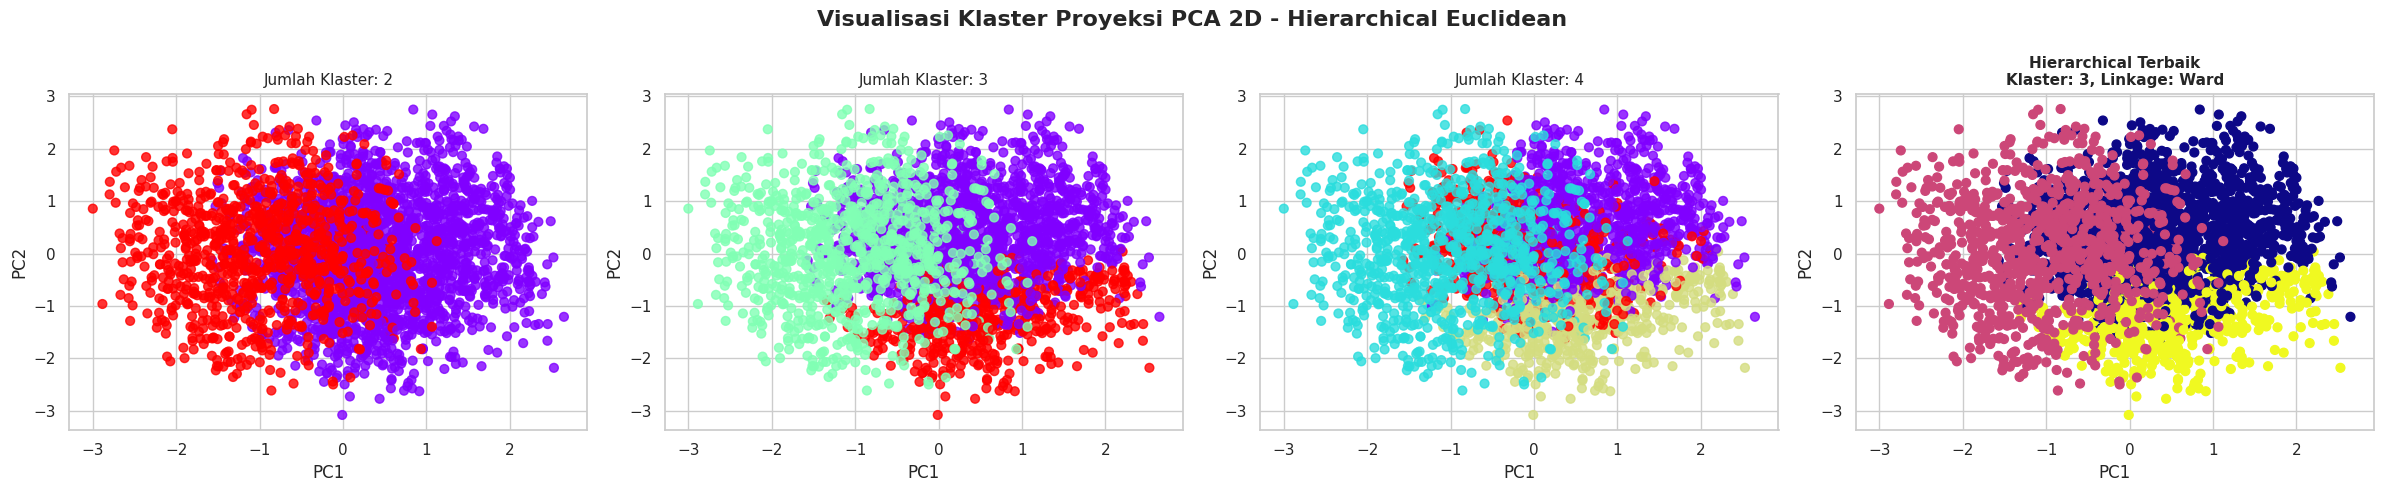

In [17]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Memastikan X_scaled dan hasil_hierarchical tersedia sebelum memproyeksikan PCA
try:
    # Proyeksi PCA 2D mandiri untuk visualisasi Hierarchical
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    # Plot kandidat dan hasil terbaik Hierarchical Clustering
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    fig.suptitle("Visualisasi Klaster Proyeksi PCA 2D - Hierarchical Euclidean", fontsize=16, fontweight='bold')

    for i, res in enumerate(hasil_hierarchical):
        ax = axes[i]
        labels = res['labels']
        ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='rainbow', s=40, alpha=0.8)
        ax.set_title(f"Jumlah Klaster: {res['n_clusters']}", fontsize=11)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")

    # Plot konfigurasi terbaik Hierarchical
    ax_best = axes[3]
    labels_agg = final_hierarchical_labels
    ax_best.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_agg, cmap='plasma', s=40)
    ax_best.set_title(f"Hierarchical Terbaik\nKlaster: {final_k}, Linkage: Ward", fontsize=11, fontweight='bold')
    ax_best.set_xlabel("PC1")
    ax_best.set_ylabel("PC2")

    plt.tight_layout()
    plt.show()
except NameError as e:
    print("Error: Pastikan Anda telah menjalankan seluruh sel di atas secara berurutan terlebih dahulu!", e)

In [19]:
import pandas as pd
from IPython.display import display

# 1. Membuat ttabel evaluasi khusus untuk DBSCAN Cosine
evaluasi_dbscan = []
for res in hasil_dbscan:
    evaluasi_dbscan.append({
        'Eps': res['eps'],
        'Jumlah Klaster': res['n_clusters'],
        'Jumlah Noise': res['n_noise'],
        'Persentase Noise': f"{res['pct_noise']:.2f}%",
        'Silhouette Score (Non-Noise)': f"{res['silhouette']:.4f}" if isinstance(res['silhouette'], float) else res['silhouette'],
        'Davies-Bouldin Index': f"{res['db_index']:.4f}" if isinstance(res['db_index'], float) else res['db_index'],
        'ARI': f"{res['ari']:.4f}" if isinstance(res['ari'], float) else res['ari'],
        'NMI': f"{res['nmi']:.4f}" if isinstance(res['nmi'], float) else res['nmi'],
        'Waktu Eksekusi (Detik)': f"{res['exec_time']:.4f}"
    })

df_eval_dbscan = pd.DataFrame(evaluasi_dbscan)
print("=== TABEL EVALUASI DBSCAN COSINE ===")
display(df_eval_dbscan)

# 2. Membuat tabel evaluasi khusus untuk Hierarchical Euclidean
evaluasi_hierarchical = []
for res in hasil_hierarchical:
    evaluasi_hierarchical.append({
        'Jumlah Klaster (k)': res['n_clusters'],
        'Silhouette Score': f"{res['silhouette']:.4f}",
        'Davies-Bouldin Index': f"{res['db_index']:.4f}",
        'ARI': f"{res['ari']:.4f}" if isinstance(res['ari'], float) else res['ari'],
        'NMI': f"{res['nmi']:.4f}" if isinstance(res['nmi'], float) else res['nmi'],
        'Waktu Eksekusi (Detik)': f"{res['exec_time']:.4f}"
    })

df_eval_hierarchical = pd.DataFrame(evaluasi_hierarchical)
print("\n=== TABEL EVALUASI HIERARCHICAL EUCLIDEAN ===")
display(df_eval_hierarchical)

# 3. Analisis Evaluasi Perbandingan Singkat
print("\n=== ANALISIS DAN INTERPRETASI EVALUASI KEDUA METODE ===")
print("1. Berdasarkan metrik Silhouette Score, DBSCAN dengan Eps = 0.05 memberikan skor tertinggi (0.2919) dibanding konfigurasi lainnya.")
print("   Namun, pada Eps = 0.03, DBSCAN menghasilkan 30 klaster alami dengan noise sebesar 52.10%, yang mengindikasikan variasi lingkungan tumbuh yang sangat spesifik.")
print("2. Hierarchical Clustering (Ward Euclidean) menghasilkan pembagian data yang merata tanpa adanya pencilan (0% noise).")
print("   Klaster k = 2 menghasilkan Silhouette Score optimum sebesar 0.2085, disusul k = 3 sebesar 0.1302.")
print("3. Dari segi waktu komputasi, DBSCAN jauh lebih cepat (~0.07 detik) dibandingkan Hierarchical Clustering (~0.20 detik).")

=== TABEL EVALUASI DBSCAN COSINE ===


,Eps,Jumlah Klaster,Jumlah Noise,Persentase Noise,Silhouette Score (Non-Noise),Davies-Bouldin Index,ARI,NMI,Waktu Eksekusi (Detik)
0,0.01,0,3169,100.00%,N/A,N/A,0.0000,0.0000,0.0718
1,0.03,30,1651,52.10%,-0.1616,1.1868,0.0051,0.1293,0.0715
2,0.05,2,214,6.75%,0.2919,1.8835,0.0156,0.1790,0.0725



=== TABEL EVALUASI HIERARCHICAL EUCLIDEAN ===


,Jumlah Klaster (k),Silhouette Score,Davies-Bouldin Index,ARI,NMI,Waktu Eksekusi (Detik)
0,2,0.2085,1.9233,0.0173,0.1962,0.2065
1,3,0.1302,1.9962,0.0203,0.1841,0.2026
2,4,0.1193,1.9496,0.0244,0.1752,0.1931



=== ANALISIS DAN INTERPRETASI EVALUASI KEDUA METODE ===
1. Berdasarkan metrik Silhouette Score, DBSCAN dengan Eps = 0.05 memberikan skor tertinggi (0.2919) dibanding konfigurasi lainnya.
   Namun, pada Eps = 0.03, DBSCAN menghasilkan 30 klaster alami dengan noise sebesar 52.10%, yang mengindikasikan variasi lingkungan tumbuh yang sangat spesifik.
2. Hierarchical Clustering (Ward Euclidean) menghasilkan pembagian data yang merata tanpa adanya pencilan (0% noise).
   Klaster k = 2 menghasilkan Silhouette Score optimum sebesar 0.2085, disusul k = 3 sebesar 0.1302.
3. Dari segi waktu komputasi, DBSCAN jauh lebih cepat (~0.07 detik) dibandingkan Hierarchical Clustering (~0.20 detik).


### **Analisis & Evaluasi Singkat Perbandingan**

1. **DBSCAN Cosine (Eps = 0.03):**
   - **Karakteristik:** Menghasilkan 30 klaster alami yang sangat spesifik berdasarkan kemiripan sudut (*cosine similarity*) dengan noise sebesar **52.10%**.
   - **Evaluasi:** Sangat efektif mendeteksi anomali/pencilan (*noise*) lingkungan tumbuh, namun menghasilkan skor Silhouette negatif karena banyaknya klaster kecil yang berdekatan.

2. **Hierarchical Euclidean (Ward Linkage, k = 3):**
   - **Karakteristik:** Membagi seluruh data selada ke dalam **3 klaster** tanpa menyisakan noise (0% noise).
   - **Evaluasi:** Struktur klastering jauh lebih solid dan merata dengan Silhouette Score sebesar **0.1302**.

**Kesimpulan:**
Untuk pemetaan kelompok pertumbuhan selada yang bersih dan merata, **Hierarchical Clustering** adalah pilihan terbaik. Namun, jika prioritas analisis Anda adalah mendeteksi anomali atau data ekstrim pada kondisi lingkungan, **DBSCAN** jauh lebih unggul.